# 06 — Explainability (Phase 4)

**Research questions answered here**
1. *Why* does the model think a bus will be late? Which factors matter overall, and for one specific trip?
2. Can the model be summarised as simple **if-then rules** a planner can read, and how faithful are they?
3. *What if*: which planner-controllable change (running time, frequency) would lower the risk, and how do weather or a live delay change it?
4. Are the explanations **stable** (do two different boosting libraries agree on why)?
5. Can an LLM (OpenAI) turn the explanation into plain language **without inventing facts**, and what happens when the key fails?

> **What** · **Why** · **How** · **Result** · **Finding** · **Decision**

| Tool | Answers | Code |
|---|---|---|
| TreeSHAP (exact, XGBoost native) | global + local "why" | `src/xai/shap_analysis.py` |
| Surrogate tree (depth 4) | readable rules + fidelity | `src/xai/rules.py` |
| What-if | planner / dispatcher scenarios | `src/xai/counterfactual.py` |
| Narrator + OpenAI | plain-language text, fact check, fallback | `src/xai/narrator.py`, `src/xai/llm_client.py` |

In [1]:
import sys, json, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, shap
from src.config import REPORTS, FIG_DIR
from src.encoding import feature_list, apply_levels
from src.xai.feature_text import label
from src.xai.shap_analysis import XAI_DIR, load_model, threshold
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save(n): plt.tight_layout(); plt.savefig(FIG_DIR / f'p4_{n}.png', bbox_inches='tight'); plt.show()
S = {m: pd.read_parquet(XAI_DIR / f'shap_{m}.parquet') for m in ('planning', 'operational')}
FEATS = {m: feature_list(m) for m in S}
def shap_matrix(m): return S[m][[f'shap__{f}' for f in FEATS[m]]].values
print({m: len(d) for m, d in S.items()}, 'rows; base value p =', {m: round(1/(1+np.exp(-d.base_value.iloc[0])), 3) for m, d in S.items()})

{'planning': 50000, 'operational': 50000} rows; base value p = {'planning': np.float64(0.294), 'operational': np.float64(0.288)}


## 1. Sanity check: SHAP values add up to the model output
**What:** for every explained row, base value + Σ SHAP = model log-odds (the *local accuracy* property).
**Why:** if this fails, every later chart is wrong. It is asserted in `shap_analysis.py`; re-checked here.
**How:** 50,000 test events (Nov–Dec), stratified by the label, explained with XGBoost's exact TreeSHAP (`pred_contribs=True`).

In [2]:
for m in S:
    d = S[m]
    err = np.abs(shap_matrix(m).sum(1) + d.base_value - d.logit).max()
    print(f'{m:12s} max |base + sum(SHAP) - logit| = {err:.2e}')

planning     max |base + sum(SHAP) - logit| = 5.78e-06
operational  max |base + sum(SHAP) - logit| = 2.55e-05


## 2. Global importance: what drives delay risk overall?
**What:** mean |SHAP| per feature (log-odds), and summed per feature group.
**Why:** SHAP importance is measured on held-out data and is consistent (unlike split counts / gain); grouping answers the
project's research question (which data source matters) from the model's own point of view, complementing the P3 ablation.

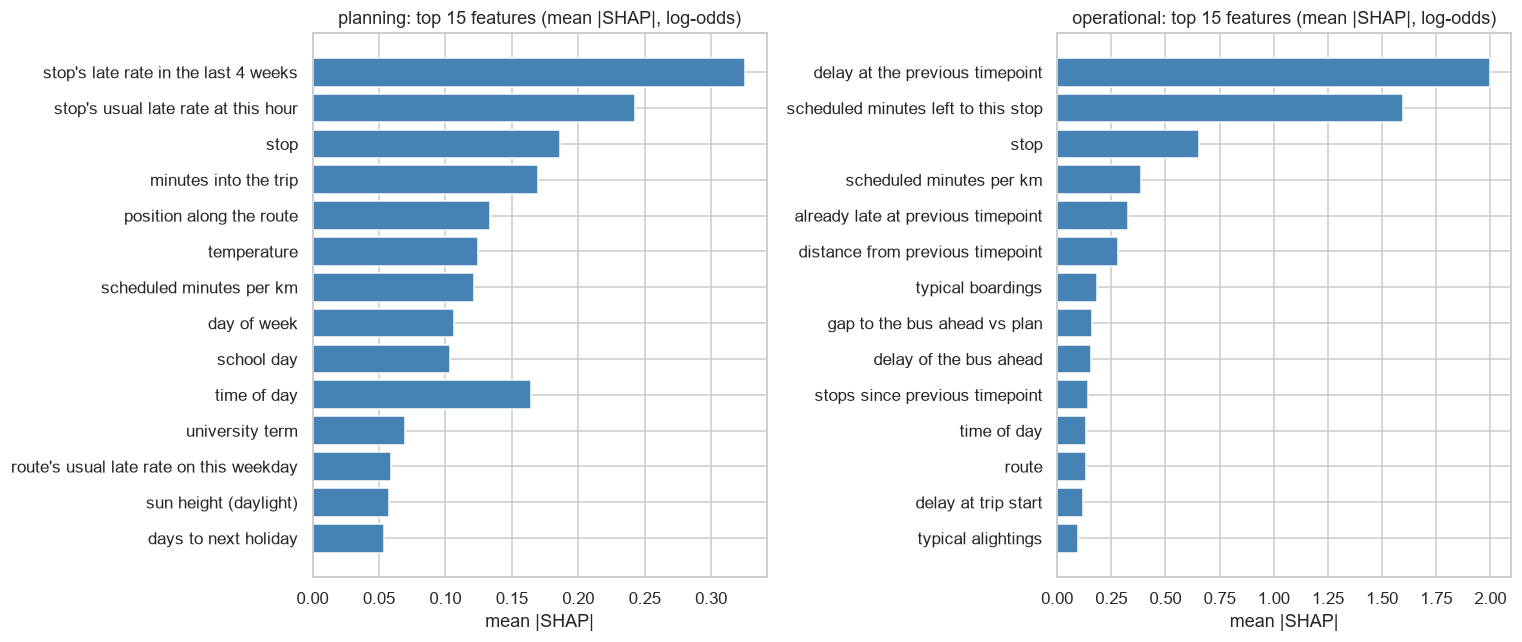

planning                           operational               \
                 feature     group share_%             feature        group   
rank                                                                          
1        recent_stop_28d   history   12.34       prev_tp_delay  operational   
2         hist_stop_hour   history    9.19   min_since_prev_tp  operational   
3                stop_id   spatial    7.04             stop_id      spatial   
4          min_into_trip   spatial    6.44  schedule_tightness         gtfs   
5               hour_sin  temporal    6.24     prev_tp_delayed  operational   
6               stop_pos   spatial    5.06          segment_km         gtfs   
7         temperature_2m   weather    4.73       avg_boardings    ridership   
8     schedule_tightness      gtfs    4.59  prev_bus_gap_ratio  operational   
9                    dow  temporal    4.04      prev_bus_delay  operational   
10         is_school_day  calendar    3.92       stops_between         gtfs   

              
     share_%  
rank          
1      24.91  
2      19.91  
3       8.19  
4       4.83  
5       4.11  
6       3.48  
7       2.30  
8       2.03  
9       1.94  
10      1.75

In [3]:
G = {m: pd.read_csv(XAI_DIR / f'shap_global_{m}.csv') for m in S}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, m in zip(axes, S):
    g = G[m].head(15).iloc[::-1]
    ax.barh([label(f) for f in g.feature], g.mean_abs_shap, color='steelblue')
    ax.set(title=f'{m}: top 15 features (mean |SHAP|, log-odds)', xlabel='mean |SHAP|')
save('global_importance')
pd.concat({m: G[m].head(10).set_index('rank')[['feature', 'group', 'share_%']] for m in S}, axis=1).round(2)

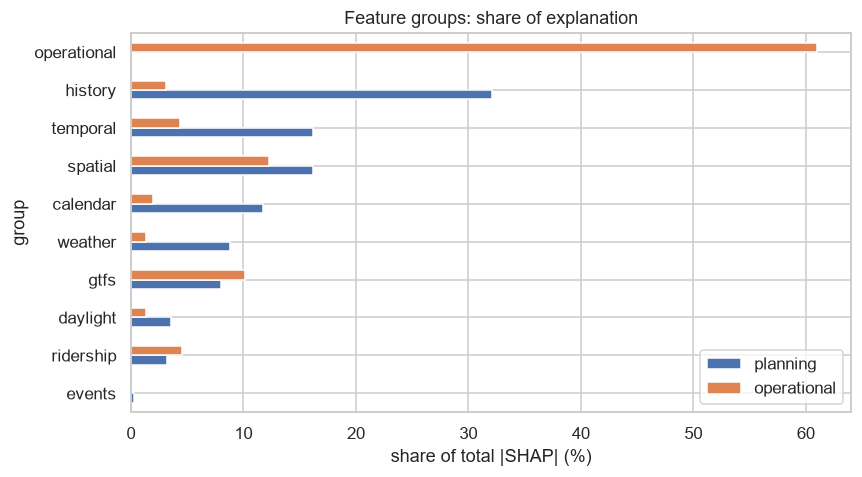

,planning,operational
group,,
history,32.1,3.1
temporal,16.2,4.4
spatial,16.2,12.3
calendar,11.7,2.0
weather,8.8,1.3
gtfs,8.0,10.1
daylight,3.6,1.3
ridership,3.2,4.5
events,0.3,0.0


In [4]:
GR = pd.concat({m: pd.read_csv(XAI_DIR / f'shap_groups_{m}.csv').set_index('group')['share_%'] for m in S}, axis=1).round(1)
ax = GR.sort_values('planning').plot.barh(figsize=(8, 4.5)); ax.set(xlabel='share of total |SHAP| (%)', title='Feature groups: share of explanation')
save('group_importance'); GR.sort_values('planning', ascending=False)

**Finding.** *Planning model:* history features explain the largest share (**32 %** of total |SHAP|). The top two features are the
stop's recent 28-day late rate (12.3 %) and its usual late rate at this hour (9.2 %). Next come temporal (16 %), spatial (16 %),
calendar (12 %), weather (9 %) and GTFS schedule design (8 %). *Operational model:* the live features take **61 %**; the delay at the
previous timepoint and the minutes since it alone account for 45 %. This matches the P3 ablation, where adding the operational group
raised AUC from 0.73 to 0.98.

**Caveat (temperature).** Temperature is the 7th planning feature (4.7 %), but in P3 the weather group added almost no AUC. The SHAP
values show why: colder means *lower* predicted risk (−0.22 log-odds below 0 °C), and the test months behave the same way
(mean SHAP −0.07 in November, −0.16 in December). Temperature is mostly acting as a **season proxy** (the low-demand December holiday
period), not as a causal weather effect. SHAP explains the *model*, not the world, so we report it that way.

**Decision.** Explanations shown to users are grouped by data source (history, time, place, schedule, weather, live). Temperature is
labelled "season/temperature" in the dashboard and is never presented as a cause.

## 3. Direction of effects (beeswarm)
**What:** each dot is one stop event; colour = feature value, x = SHAP (push towards late > 0).
**Why:** importance says *how much*, the beeswarm says *which way*, e.g. high historical late rate → higher risk.

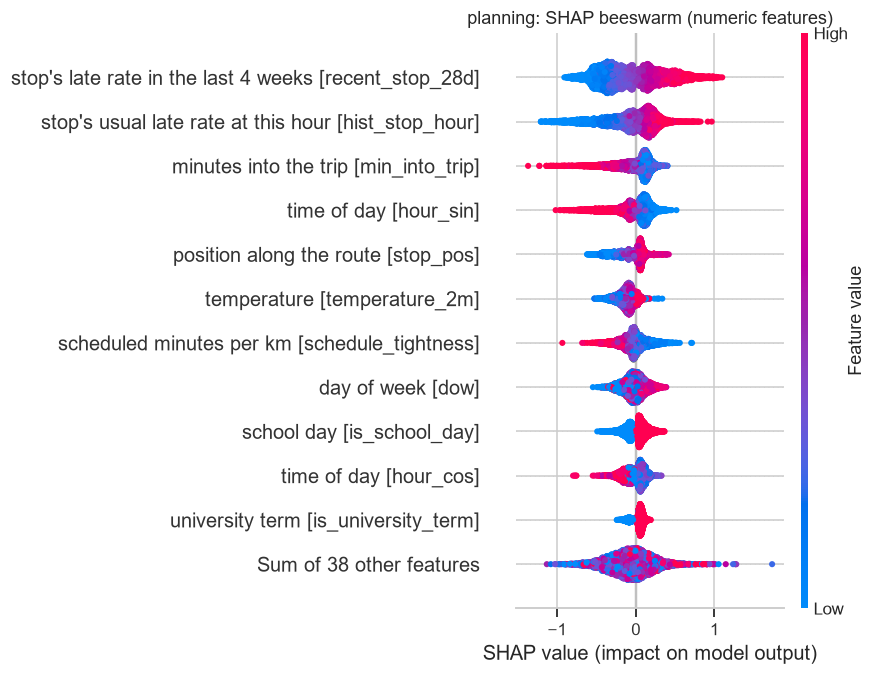

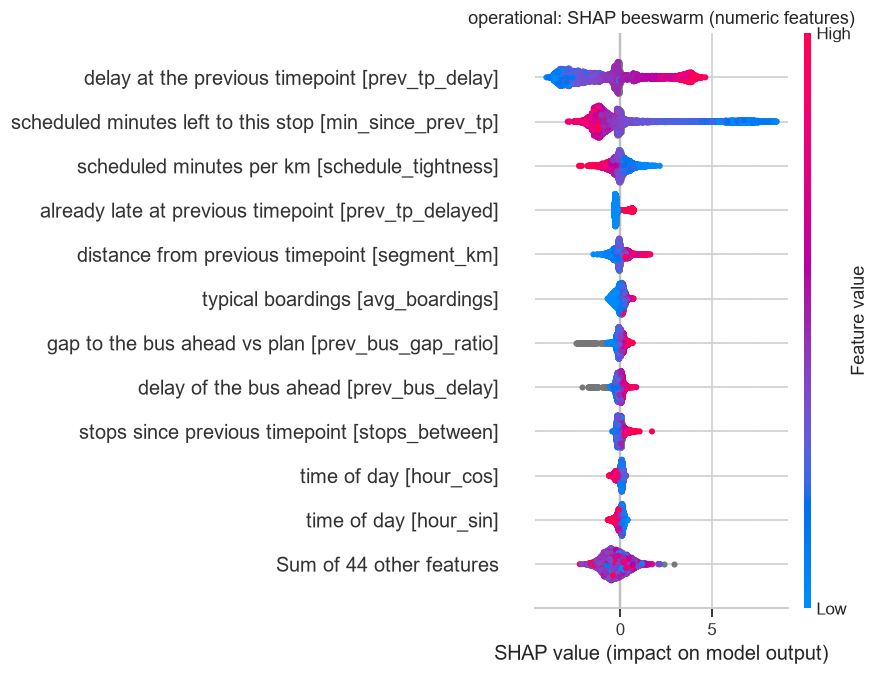

In [5]:
for m in S:
    num = [f for f in FEATS[m] if S[m][f].dtype.kind in 'fiub']
    idx = [FEATS[m].index(f) for f in num]
    sub = S[m].sample(8000, random_state=0)
    ex = shap.Explanation(values=sub[[f'shap__{f}' for f in num]].values, data=sub[num].astype(float).values,
                          feature_names=[label(f) + f' [{f}]' for f in num])
    shap.plots.beeswarm(ex, max_display=12, show=False); plt.title(f'{m}: SHAP beeswarm (numeric features)'); save(f'beeswarm_{m}')

## 4. Dependence: *how* do the main factors change the risk?
**What:** SHAP value vs feature value for the key planning drivers (+ the live delay in operational mode).
**Why:** answers questions like "from what historical late rate does risk take off?" or "does a tight schedule (min/km) really hurt?"

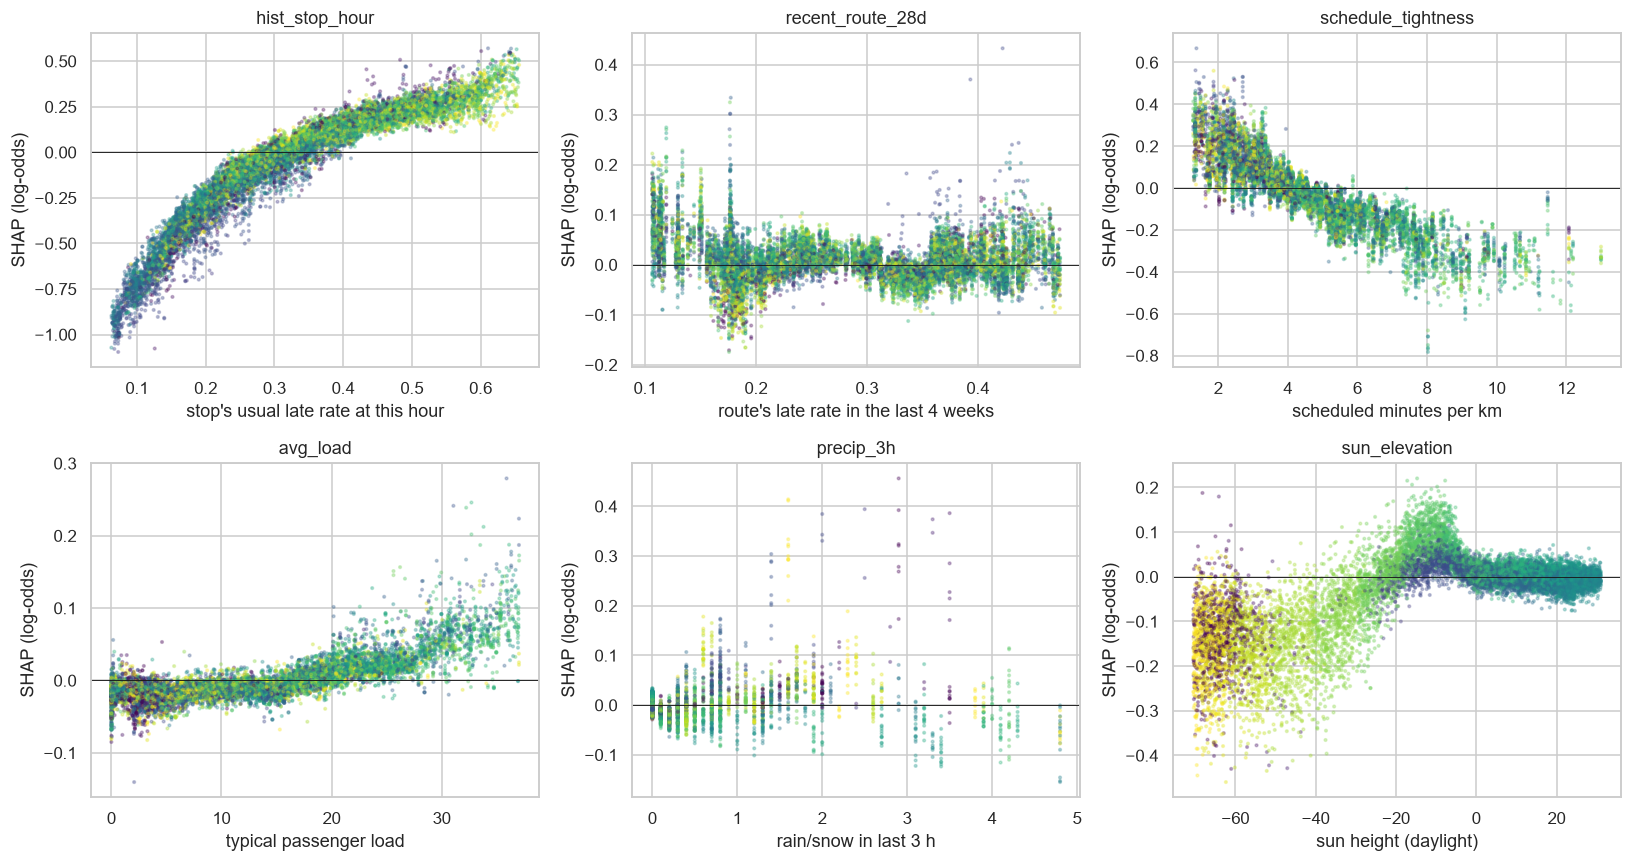

In [6]:
plan = ['hist_stop_hour', 'recent_route_28d', 'schedule_tightness', 'avg_load', 'precip_3h', 'sun_elevation']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
d = S['planning'].sample(15000, random_state=1)
for ax, f in zip(axes.flat, plan):
    x = d[f].astype(float); q = x.quantile([0.01, 0.99])
    ok = x.between(*q)
    ax.scatter(x[ok], d[f'shap__{f}'][ok], s=3, alpha=0.3, c=d.hour[ok], cmap='viridis')
    ax.axhline(0, color='k', lw=0.6); ax.set(xlabel=label(f), ylabel='SHAP (log-odds)', title=f)
save('dependence_planning')

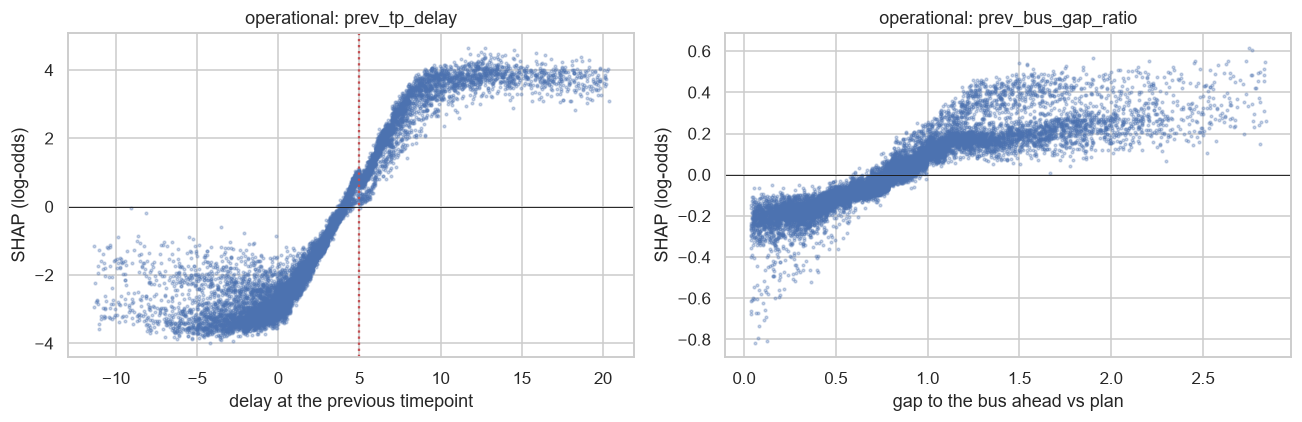

In [7]:
d = S['operational'].sample(15000, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, f in zip(axes, ['prev_tp_delay', 'prev_bus_gap_ratio']):
    x = d[f].astype(float); ok = x.between(*x.quantile([0.01, 0.99]))
    ax.scatter(x[ok], d[f'shap__{f}'][ok], s=3, alpha=0.3); ax.axhline(0, color='k', lw=0.6)
    ax.axvline(5, color='r', ls=':') if f == 'prev_tp_delay' else None
    ax.set(xlabel=label(f), ylabel='SHAP (log-odds)', title=f'operational: {f}')
save('dependence_operational')

**Finding.** The effects are monotone and plausible:
* Usual late rate at this stop-hour: SHAP rises from −0.88 (≤ 10 %) to +0.43 (> 60 %). The recent 28-day rate rises even more
  steeply, from −0.67 to +0.85, which is why it ranks first: recent conditions (roadworks, detours) matter more than the long-run
  average.
* **Schedule tightness** (scheduled min/km): tight segments (≤ 1.5 min/km) push risk *up* (+0.26 to +0.31); generous ones
  (> 6 min/km) push it *down* (−0.24). The model has learned that under-scheduled running time causes lateness.
* Crowding (average load > 40) adds +0.14. Rain has only small effects (|SHAP| < 0.06), consistent with the small weather gain in P3.
* Operational: the previous-timepoint delay effect swings from −2.9 (early or on time) to +3.8 (> 10 min late) and crosses zero
  between 4 and 5 min. A big gap behind the bus ahead (gap ratio > 2) adds +0.35; a bunched bus (< 0.25) subtracts 0.23.

**Decision.** Schedule tightness is a lever a planner controls, so it becomes the basis of the what-if analysis (§8) and of the
chronic-segment running-time suggestions in Phase 5.

## 5. Why are evening peaks late? SHAP by time period
**What:** average signed SHAP per feature group, by period of the day (planning model).
**Why:** turns "the PM peak is worse" into *which* factors make it worse, the kind of statement a planner needs.

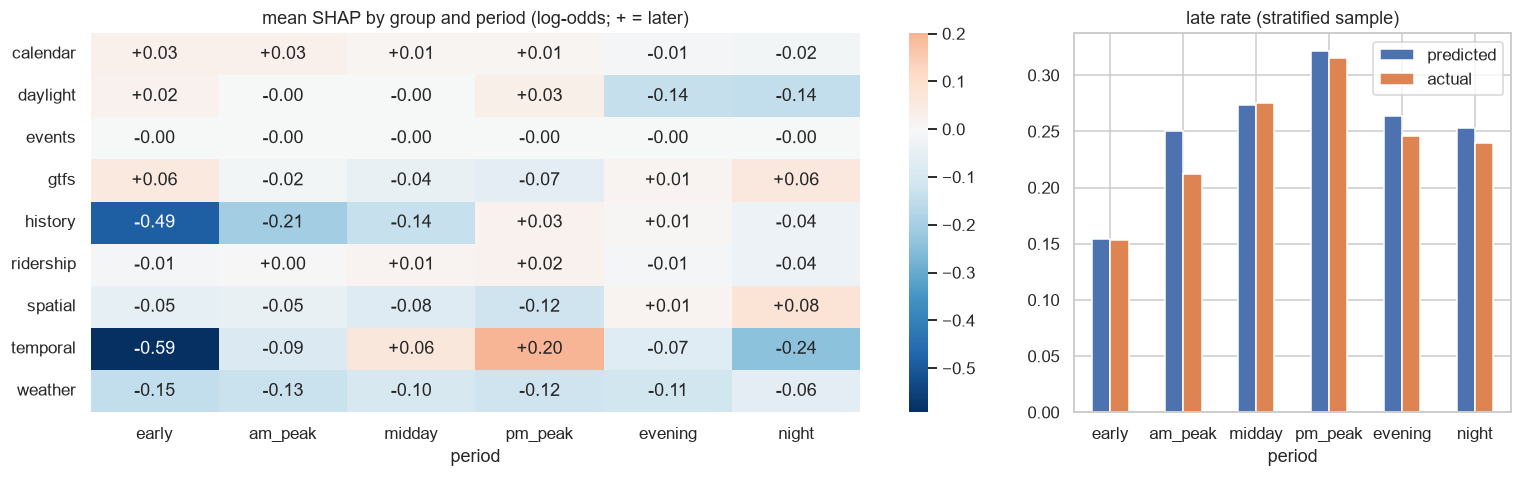

,predicted,actual
period,,
early,0.155,0.154
am_peak,0.250,0.212
midday,0.273,0.275
pm_peak,0.321,0.315
evening,0.264,0.246
night,0.253,0.240


In [8]:
from src.xai.shap_analysis import group_of
gm = group_of(); d = S['planning']
grp = pd.DataFrame({g: d[[f'shap__{f}' for f in FEATS['planning'] if gm[f] == g]].sum(1) for g in sorted(set(gm[f] for f in FEATS['planning']))})
grp['period'] = d.period.astype(str).values
per = grp.groupby('period').mean().reindex(['early', 'am_peak', 'midday', 'pm_peak', 'evening', 'night'])
late = d.groupby(d.period.astype(str)).agg(predicted=('prob', 'mean'), actual=('delayed', 'mean')).reindex(per.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})
sns.heatmap(per.T, annot=True, fmt='+.2f', cmap='RdBu_r', center=0, ax=axes[0]); axes[0].set(title='mean SHAP by group and period (log-odds; + = later)')
late.plot.bar(ax=axes[1], rot=0); axes[1].set(title='late rate (stratified sample)')
save('shap_by_period'); late.round(3)

In [9]:
# the same question per route: which routes are high-risk in which period (test predictions, all rows)
R = pd.read_csv(XAI_DIR / 'route_period_risk.csv')
R.head(12).round(3)

,route_id,direction_id,period,n,predicted,actual,lift_vs_avg
0,73,Outbound,PM peak (16-18),3995,0.587,0.601,2.400
1,39,Outbound,night (22+),4050,0.578,0.487,1.944
2,71,Outbound,PM peak (16-18),4083,0.558,0.540,2.154
3,44,Outbound,early (<7),2204,0.538,0.515,2.054
4,44,Inbound,AM peak (7-9),3721,0.519,0.465,1.858
5,39,Outbound,evening (19-21),6698,0.515,0.482,1.925
6,44,Inbound,PM peak (16-18),3762,0.507,0.454,1.812
7,44,Outbound,AM peak (7-9),3121,0.505,0.478,1.910
8,44,Outbound,PM peak (16-18),3180,0.504,0.465,1.857
9,34E,Outbound,PM peak (16-18),5303,0.495,0.530,2.117


**Finding.** The PM peak has the highest late rate (31.5 % actual vs 32.1 % predicted, so it is well calibrated by period). Its
explanation is mostly *time of day itself* (temporal group +0.20 log-odds) plus stops that are historically late at that hour
(history +0.03, against −0.49 in the early morning). Early morning is low risk because of both clock time (−0.59) and history (−0.49).
In the evening and at night, darkness (daylight group −0.14) lowers the risk, which reflects lighter traffic rather than darkness
itself. Weather is negative in every period (−0.06 to −0.15), the season-proxy effect noted above. By route, the riskiest
route-direction-periods are 73 Outbound in the PM peak (60 % actually late, 2.4× the average), 71 Outbound in the PM peak, 39 Outbound
at night/evening, and route 44 in almost every period.

**Decision.** The route × period risk table (`route_period_risk.csv`) goes into the Planner Insights page, because it tells a
planner *where and when* to look first.

## 6. Local explanations: one trip at a time
**What:** waterfall plots for three real test events: a confident *late* call, a confident *on-time* call and a borderline one.
**Why:** this is exactly what a dispatcher sees in the dashboard: the prediction and the few factors that produced it.

high risk: route 44 Outbound, stop 40001, 2025-11-18 01:00 -> p=1.00, actual delayed=1


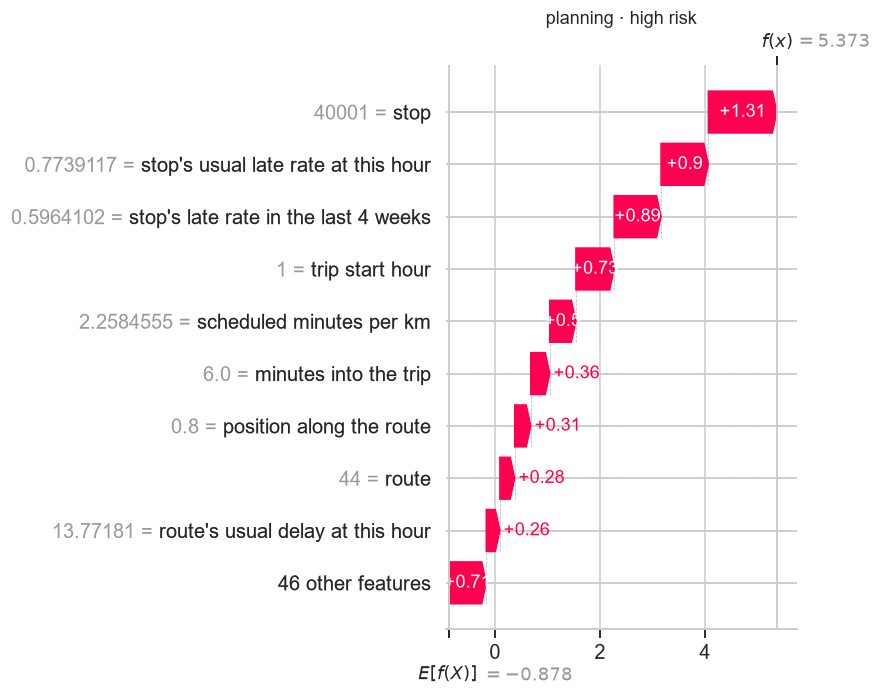

low risk: route 116 Inbound, stop 8309, 2025-11-02 05:00 -> p=0.00, actual delayed=0


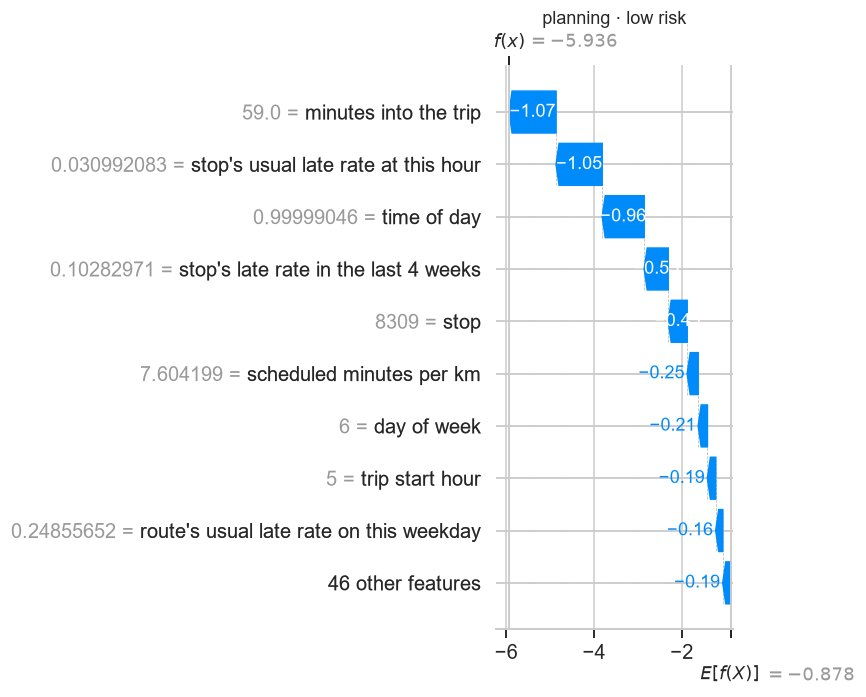

borderline: route 77 Outbound, stop 7922, 2025-11-06 10:00 -> p=0.27, actual delayed=0


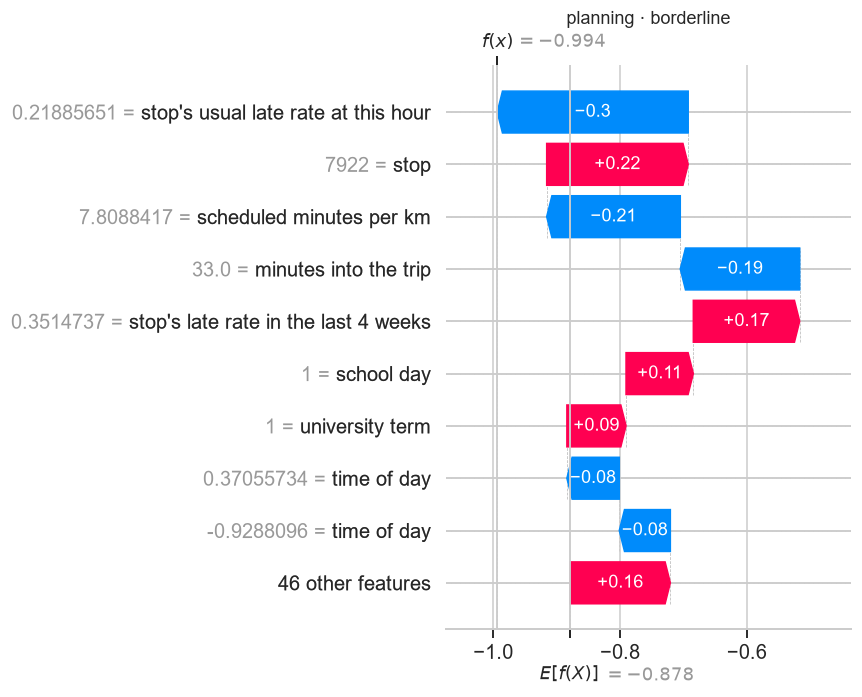

In [10]:
d = S['planning']; thr = threshold('planning')
cases = {'high risk': d.prob.idxmax(), 'low risk': d.prob.idxmin(), 'borderline': (d.prob - thr).abs().idxmin()}
for name, i in cases.items():
    r = d.loc[i]
    ex = shap.Explanation(values=r[[f'shap__{f}' for f in FEATS['planning']]].values.astype(float), base_values=float(r.base_value),
                          data=[str(r[f]) for f in FEATS['planning']], feature_names=[label(f) for f in FEATS['planning']])
    print(f"{name}: route {r.route_id} {r.direction_id}, stop {r.stop_id}, {r.service_date:%Y-%m-%d} {int(r.hour):02d}:00 -> p={r.prob:.2f}, actual delayed={int(r.delayed)}")
    shap.plots.waterfall(ex, max_display=10, show=False); plt.title(f'planning · {name}'); save(f'waterfall_{name.replace(" ", "_")}')

## 7. Readable rules: a surrogate decision tree
**What:** a depth-4 regression tree trained to mimic the XGBoost probability using only readable features.
**Why:** planners want statements like "evening peak + stop usually late → high risk". A surrogate explains the *model*, so we must
report **fidelity**: R² against XGBoost probabilities and ROC-AUC on the real labels, measured on test rows the surrogate never saw
(it was fitted on validation).

In [11]:
FID = pd.read_csv(XAI_DIR / 'surrogate_fidelity.csv'); display(FID.round(3))
from src.xai.rules import rule_sentence
L = pd.read_csv(XAI_DIR / 'rule_leaves_planning.csv')
L['rule (plain)'] = L.rule.map(rule_sentence)
display(L[['surrogate_p', 'actual_late', 'share_%', 'rule (plain)']].round(3).head(8))
print(open(XAI_DIR / 'rules_planning.txt', encoding='utf-8').read()[:2500])

,mode,depth,leaves,r2_vs_xgb,auc_surrogate,auc_xgb
0,planning,4,16,0.380,0.683,0.754
1,operational,4,14,0.894,0.951,0.977


,surrogate_p,actual_late,share_%,rule (plain)
0,0.718,0.618,1.074,stop's usual late rate at this hour above 65%;...
1,0.558,0.450,1.160,stop's usual late rate at this hour between 32...
2,0.549,0.438,16.476,stop's usual late rate at this hour between 42...
3,0.439,0.339,9.146,stop's usual late rate at this hour between 32...
4,0.422,0.344,1.742,stop's usual late rate at this hour above 45%;...
5,0.410,0.320,4.612,stop's usual late rate at this hour between 18...
6,0.344,0.257,4.218,stop's usual late rate at this hour between 32...
7,0.312,0.253,8.218,stop's usual late rate at this hour between 18...


|--- hist_stop_hour <= 0.32
|   |--- hist_stop_hour <= 0.18
|   |   |--- hist_stop_hour <= 0.11
|   |   |   |--- hist_stop_hour <= 0.08
|   |   |   |   |--- value: [0.06]
|   |   |   |--- hist_stop_hour >  0.08
|   |   |   |   |--- value: [0.10]
|   |   |--- hist_stop_hour >  0.11
|   |   |   |--- recent_route_28d <= 0.32
|   |   |   |   |--- value: [0.14]
|   |   |   |--- recent_route_28d >  0.32
|   |   |   |   |--- value: [0.22]
|   |--- hist_stop_hour >  0.18
|   |   |--- recent_route_28d <= 0.32
|   |   |   |--- recent_route_28d <= 0.23
|   |   |   |   |--- value: [0.19]
|   |   |   |--- recent_route_28d >  0.23
|   |   |   |   |--- value: [0.25]
|   |   |--- recent_route_28d >  0.32
|   |   |   |--- stop_pos <= 0.62
|   |   |   |   |--- value: [0.31]
|   |   |   |--- stop_pos >  0.62
|   |   |   |   |--- value: [0.41]
|--- hist_stop_hour >  0.32
|   |--- recent_route_28d <= 0.30
|   |   |--- recent_route_28d <= 0.24
|   |   |   |--- scheduled_headway <= 12.50
|   |   |   |   |---

**Finding.** Readable rules work well for the **operational** model: a depth-4 tree (14 leaves) reproduces XGBoost with R² = 0.89 and
AUC 0.951 (vs 0.977), e.g. *"delay at the previous timepoint > 6.8 min and not at the last stops → 99 % late"*. For the **planning**
model, a 16-leaf tree reaches only R² 0.38 and AUC 0.683, below even the P3 decision tree (0.700). The depth sweep shows the
trade-off: 284 leaves (depth 12) still give only R² 0.48 / AUC 0.696. Planning risk is spread over many small interacting effects
that no short rule list captures. The top planning rule is *"stop usually late at this hour (> 65 %) and route late in the last 4
weeks (> 30 %) → 72 % (actual 62 %)"*. The surrogate's probabilities run about 10 points high on test because it was fitted on
validation months with a higher late rate (32.8 % vs 25.1 %); its *ranking* is what matters.

**Decision.** Rules are shown as a *summary* with the fidelity printed next to them. Planners are told the rules cover the main
pattern and that individual predictions should use the SHAP explanation. This is an honest limitation of global surrogates for
diffuse models.

## 8. What-if: what could a planner change?
**What:** for the high-risk event from §6: (a) add scheduled running time on the segment, (b) change the planned headway,
(c) different weather. Operational: how the risk grows with the delay at the previous timepoint.
**Why:** an explanation is most useful when it points to an action. **Caveat:** these are *model-based* what-ifs, i.e. associations
learned from 2025 data, not causal effects.

case: route 73 Outbound, stop 2125, 2025-11-07 19:00, scheduled 5.0 min over 1.79 km -> p=0.80
{'possible': False, 'p_before': 0.8, 'p_after': 0.803, 'reason': 'adding up to 10 min is not enough according to the model'}


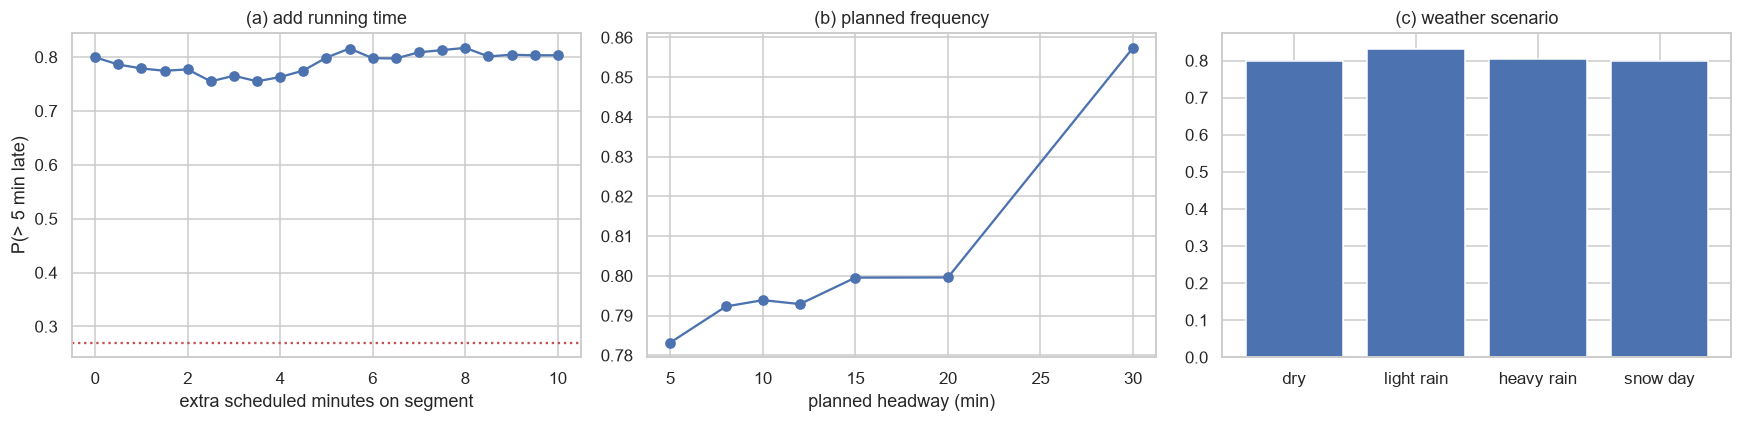

,scenario,prob
0,dry,0.800
1,light rain,0.832
2,heavy rain,0.804
3,snow day,0.800


In [12]:
from src.xai.counterfactual import what_if, weather_scenarios, minimal_schedule_change, schedule_fix_population, delay_tipping_points
mp = load_model('planning'); d = S['planning']; thr = threshold('planning')
# Decision: the single highest-risk event is a 01:00 night trip with p~1.0, which is not actionable and not typical.
# Use a realistic planner case instead: weekday daytime (7-19 h), clearly above the alert threshold but not saturated (0.5-0.8),
# with a known segment running time of at least 3 scheduled minutes.
cand = d[d.seg_sched_min.ge(3) & d.hour.between(7, 19) & (d.is_weekend == 0) & d.prob.between(0.5, 0.8)].sort_values('prob', ascending=False)
row = apply_levels(cand.iloc[[0]].copy()); r0 = row.iloc[0]
print(f"case: route {r0.route_id} {r0.direction_id}, stop {r0.stop_id}, {r0.service_date:%Y-%m-%d} {int(r0.hour):02d}:00, scheduled {r0.seg_sched_min:.1f} min over {r0.segment_km:.2f} km -> p={r0.prob:.2f}")
res = minimal_schedule_change(mp, row, 'planning', threshold=thr)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res.items() if k != 'curve'})
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
c = res['curve']; axes[0].plot(c.added_min, c.prob, marker='o'); axes[0].axhline(thr, color='r', ls=':')
axes[0].set(xlabel='extra scheduled minutes on segment', ylabel='P(> 5 min late)', title='(a) add running time')
hw = what_if(mp, row, 'planning', 'scheduled_headway', [5, 8, 10, 12, 15, 20, 30])
axes[1].plot(hw.scheduled_headway, hw.prob, marker='o'); axes[1].set(xlabel='planned headway (min)', title='(b) planned frequency')
ws = weather_scenarios(mp, row, 'planning'); axes[2].bar(ws.scenario, ws.prob); axes[2].set(title='(c) weather scenario')
save('what_if_planning'); ws.round(3)

In [13]:
# Population view: all high-risk daytime events (p >= alert threshold) with a known segment time in the SHAP sample
hi = apply_levels(d[d.seg_sched_min.ge(1) & d.hour.between(6, 21) & (d.prob >= thr)].copy())
fix = schedule_fix_population(mp, hi, 'planning', thr)
share = {f'<= {a} min': round(float((fix.min_add <= a).mean() * 100), 1) for a in (1, 2, 3, 5, 10)}
print(f'{len(hi):,} high-risk daytime events; share pushed below the alert threshold by adding ...', share)
mean_curve = fix[[c for c in fix if c.startswith('p_+')]].mean()
print('mean probability after adding minutes:', mean_curve.round(3).to_dict())
WF = pd.Series(share, name='% of high-risk events fixed'); WF.to_frame()

16,103 high-risk daytime events; share pushed below the alert threshold by adding ... {'<= 1 min': 10.2, '<= 2 min': 17.2, '<= 3 min': 21.8, '<= 5 min': 26.4, '<= 10 min': 29.3}
mean probability after adding minutes: {'p_+0': 0.4490000009536743, 'p_+1': 0.41999998688697815, 'p_+2': 0.4009999930858612, 'p_+3': 0.3880000114440918, 'p_+4': 0.38100001215934753, 'p_+5': 0.3779999911785126, 'p_+7.5': 0.375, 'p_+10': 0.3790000081062317}


,% of high-risk events fixed
<= 1 min,10.2
<= 2 min,17.2
<= 3 min,21.8
<= 5 min,26.4
<= 10 min,29.3


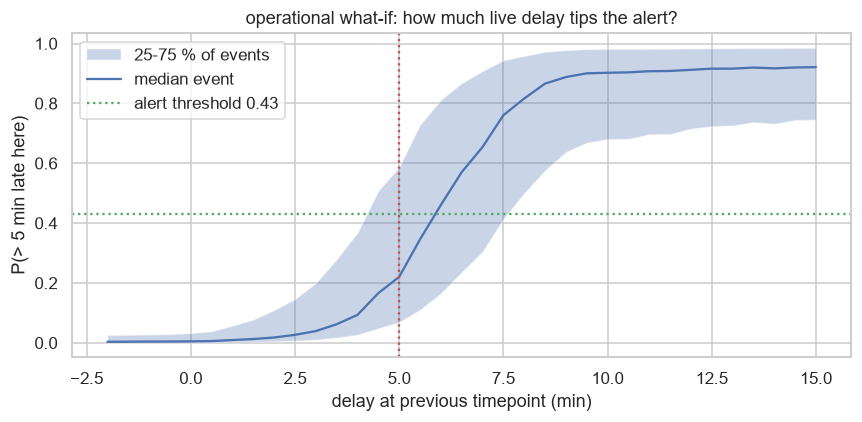

tipping point (min of previous-timepoint delay) over 2,000 events:
count    1808.00
mean        5.12
std         3.80
min        -2.00
10%        -2.00
25%         4.00
50%         6.00
75%         7.50
90%         8.50
max        15.00
dtype: float64
share never crossing within -2..15 min: 9.6%


In [14]:
mo = load_model('operational'); o = S['operational']; othr = threshold('operational')
rows = apply_levels(o[o.prev_tp_delay.notna()].sample(2000, random_state=3).copy())
C, tip = delay_tipping_points(mo, rows, 'operational', othr)
fig, ax = plt.subplots(figsize=(8, 4))
q = C.quantile([0.25, 0.5, 0.75])
ax.fill_between(C.columns, q.loc[0.25], q.loc[0.75], alpha=0.3, label='25-75 % of events'); ax.plot(C.columns, q.loc[0.5], label='median event')
ax.axvline(5, color='r', ls=':'); ax.axhline(othr, color='g', ls=':', label=f'alert threshold {othr:.2f}')
ax.set(xlabel='delay at previous timepoint (min)', ylabel='P(> 5 min late here)', title='operational what-if: how much live delay tips the alert?')
ax.legend(); save('what_if_operational')
print('tipping point (min of previous-timepoint delay) over 2,000 events:'); print(tip.describe(percentiles=[.1, .25, .5, .75, .9]).round(2))
print('share never crossing within -2..15 min:', f'{tip.isna().mean():.1%}')

**Finding.** *Single case* (route 73 Outbound, stop 2125, Friday 19:00, p = 0.80): adding up to 10 scheduled minutes does **not**
bring the risk below the alert threshold. The risk is inherited from upstream and from the stop's history, not created on this
segment. *Population view* (16,103 high-risk daytime events): adding running time to the segment moves **10 %** below the threshold
with 1 min, **22 %** with ≤ 3 min and **29 %** with ≤ 10 min. The mean probability falls from 0.449 to 0.381 at +4 min and then
plateaus (0.379 at +10). There are clear **diminishing returns after about 3–4 minutes**. Weather scenarios change this case by at
most 3 points. *Operational tipping point* (2,000 events): the median event crosses the dispatcher alert when the previous timepoint
is **6 min** late (IQR 4–7.5 min). 10 % are above the threshold even when early (bus ahead, history), and 9.6 % never cross within
15 min.

**Decision.** Planner advice is framed as "a small padding (≤ 3 min) fixes about 1 in 5 high-risk stop events; the rest need upstream
or route-level action". This links directly to the propagation analysis in Phase 5. Every what-if is labelled *model-based, not
causal*.

## 9. Stability: do XGBoost and LightGBM agree on *why*?
**What:** Spearman rank correlation of global feature importance (mean |SHAP|) between the two boosting libraries, and the overlap of
their top-10 features, on the same 50 k test rows.
**Why:** if two equally accurate models explain the data very differently, explanations would be an artefact of one model. Agreement
supports trusting them.

In [15]:
ST = pd.concat([pd.read_csv(XAI_DIR / f'shap_stability_{m}.csv') for m in S]); display(ST.round(3))
for m in S:
    print(m, '- share of |SHAP| by group (%)'); display(pd.read_csv(XAI_DIR / f'shap_stability_groups_{m}.csv', index_col=0).sort_values('xgb_%', ascending=False).T)
# operational: the features where the two libraries split credit differently
pd.read_csv(XAI_DIR / 'shap_stability_features_operational.csv', index_col=0).head(10)

,mode,spearman_rho_all,top10_overlap,group_spearman,group_max_abs_diff_pts
0,planning,0.981,10,0.983,3.646
0,operational,0.545,4,0.879,5.762


planning - share of |SHAP| by group (%)


,history,spatial,temporal,calendar,weather,gtfs,ridership,daylight,events
xgb_%,28.07,25.90,16.48,9.96,8.95,5.63,2.56,2.25,0.19
lgb_%,31.72,24.29,16.03,9.51,8.58,5.32,2.03,2.34,0.18


operational - share of |SHAP| by group (%)


,operational,spatial,gtfs,temporal,ridership,history,calendar,weather,daylight,events
xgb_%,54.39,14.94,10.82,5.87,5.26,3.82,2.21,1.58,1.09,0.02
lgb_%,51.98,17.16,5.97,4.80,5.15,9.58,0.72,3.12,1.38,0.14


,xgb_%,lgb_%
prev_tp_delay,24.91,6.46
min_since_prev_tp,19.91,37.64
stop_id,8.19,1.79
schedule_tightness,4.83,1.42
prev_tp_delayed,4.11,0.01
segment_km,3.48,3.08
avg_boardings,2.30,1.54
prev_bus_gap_ratio,2.03,5.29
prev_bus_delay,1.94,1.17
stops_between,1.75,0.61


**Finding.** *Planning:* XGBoost and LightGBM agree almost perfectly on why (feature-rank ρ = 0.98, top-10 overlap 10/10, group-rank
ρ = 0.98, max group difference 3.6 points). *Operational:* feature-level agreement is weak (ρ = 0.55, top-10 overlap 4/10), but
group-level agreement is strong (ρ = 0.88; the live group gets 54 % vs 52 %). The cause is correlated features: XGBoost credits the
previous-timepoint delay (25 %), while LightGBM credits minutes since the previous timepoint (38 %) and gives the 0/1 flag
`prev_tp_delayed` almost nothing. These features carry the same information, so the credit moves between them.

**Decision.** (Decision log #23.) Stability is reported at both levels, and operational explanations are communicated by *factor
group* ("live delay information"), which is the level at which two equally accurate models agree.

## 10. Plain-language explanations with OpenAI (and what happens when the key fails)
**What:** facts (top SHAP factors converted to percentage-point effects) → template text (always) → OpenAI rewrite for a dispatcher,
planner or rider → automatic **faithfulness check** (every number must exist in the facts; the main factor must be named) → fallback.
**Why:** SHAP plots are for analysts; dispatchers and riders need one sentence. LLMs can hallucinate, so the LLM never sees the raw data,
only the fact sheet, and its output is checked.
**Key-failure handling:** `llm_client.health_check()` classifies errors (missing key, invalid/expired key 401, quota 429, rate limit, network,
unknown model), logs to `logs/llm.log` (never the key) and the dashboard shows a warning banner while falling back to templates.

In [16]:
from src.xai import llm_client, narrator
st = llm_client.health_check(force=True)
print('OpenAI status:', st.code, '-', st.message, f'(model {st.model})')
V1 = pd.read_csv(XAI_DIR / 'narrative_eval_v1_strict.csv')
print('v1 (exact-number check): LLM drafts rejected =', f'{(V1.status == "unfaithful").mean():.0%}')
EV = pd.read_csv(XAI_DIR / 'narrative_eval.csv')
print('v2 (rounding allowed):  LLM drafts rejected =', f'{(EV.status == "unfaithful").mean():.0%}', '| final texts faithful =', f'{EV.ok.mean():.0%}')
print(EV.groupby(['audience', 'source']).agg(n=('ok', 'size'), faithful=('ok', 'mean'), words=('words', 'mean')).round(2))
for _, r in EV.head(3).iterrows():
    print(f"\n[{r.audience} · {r.source}] {r.text}")

OpenAI status: ok - OpenAI connected. (model gpt-4o-mini)
v1 (exact-number check): LLM drafts rejected = 20%
v2 (rounding allowed):  LLM drafts rejected = 5% | final texts faithful = 100%
                      n  faithful  words
audience   source                       
dispatcher llm       18       1.0  69.17
           template   2       1.0  65.00
planner    llm       20       1.0  75.70
rider      llm       19       1.0  70.74
           template   1       1.0  30.00

[dispatcher · llm] The prediction for bus route 111, inbound at stop 5595 on December 2, 2025, indicates a low risk of delay, with a 6% probability of being late. The most significant factor is the stop's usual late rate at this hour, which is 7%. Other factors also lower the risk. Given the low risk level and the probability being below the alert threshold of 27%, immediate action may not be necessary.

[planner · llm] The prediction for bus route 111, inbound at stop 5595 on December 2, 2025, indicates a low risk of 

In [17]:
# fallback demo: simulate an expired key without touching the real one
import os
saved = os.environ.get('OPENAI_API_KEY', '')
os.environ['OPENAI_API_KEY'] = ''
f = json.loads(EV.facts.iloc[0])
r = narrator.llm_explanation(f, 'dispatcher')
print('status:', r['status'], '| source:', r['source']); print('warning shown in app:', r['warning']); print('text:', r['text'])
os.environ['OPENAI_API_KEY'] = saved; llm_client._STATUS = None

status: missing_key | source: template
warning shown in app: No OpenAI API key found (set OPENAI_API_KEY in .env). Using template explanations.
text: [LOW] Route 111 Inbound, stop 5595, 09:00: 6% chance of >5 min late (alert threshold 27%, typical 29%). Why: stop's usual late rate at this hour (7%) lowers the risk by 7 pts; stop's late rate in the last 4 weeks (6%) lowers the risk by 5 pts; position along the route (30% along) lowers the risk by 2 pts; route's usual late rate on this weekday (19%) lowers the risk by 1 pts.


**Finding.** OpenAI (gpt-4o-mini) was connected. On 60 narratives (20 test events × 3 audiences), the first run with an exact-number
fact check rejected **20 %** of LLM drafts. Manual inspection showed **all 12 were honest roundings** (e.g. "40 minutes" for 40.4 min).
After allowing whole-number rounding and nothing else (decision #22), **5 %** (3/60) were rejected, and all 3 were *genuine*: the LLM
swapped the main factor (minutes into the trip) for another one, or claimed the time of day was most important. Rejected drafts fall
back to the template, so **100 % of the texts shown are faithful**. LLM texts average about 70–76 words. The rider version is shorter
in the template (30 words), and all LLM rider texts include a "this is a prediction" reminder. With an empty or expired key the system returns
status `missing_key` / `invalid_key`, shows a warning banner and uses the template, so the app never breaks.

**Decision.** Keep the LLM *behind* the fact check, never as the source of truth. The human-rating rubric (`narrative_rubric.csv`,
clarity / correctness / usefulness 1–5) is provided for a reviewer instead of using an LLM as a judge.

## Phase 4 summary

| Question | Answer | Evidence |
|---|---|---|
| What drives planned risk? | stop/route late history (32 %), time of day (16 %), place (16 %), calendar (12 %) | SHAP groups |
| What drives live risk? | delay at the previous timepoint and time since it (61 % live group) | SHAP groups |
| Is the model sensible? | monotone, plausible effects; tight schedules raise risk | dependence |
| Can it be written as rules? | operational yes (R² 0.89); planning only roughly (R² 0.38) | surrogate fidelity |
| What can a planner change? | ≤ 3 min padding fixes ~22 % of high-risk events; diminishing returns after that | population what-if |
| When should a dispatcher act? | median tipping point is 6 min late at the previous timepoint | operational what-if |
| Are explanations stable? | yes at group level (ρ 0.98 / 0.88) | XGB vs LGB |
| Can an LLM explain safely? | yes with a fact check: 5 % of drafts rejected, 100 % of shown texts faithful | narrative evaluation |

**Next (Phase 5):** the what-ifs show that most late risk is *inherited* from upstream. Phase 5 measures this directly (delay
propagation, recovery), adds severity and minutes-late predictions, detects bunching, and lists chronic segments that persist out of
time.